# NB1 · Train a credit-scoring model
**AI & Machine Learning in Finance · Lecture 1 hands-on (part 2)**

You will train three models that predict whether an applicant will **default** (*დეფოლტი*), test them honestly, choose a cut-off, and score **Nino**.

**Key words** · feature · *მახასიათებელი*, label · *სამიზნე ცვლადი*, train/test split · *სასწავლო/სატესტო დაყოფა*, decision tree · *გადაწყვეტილების ხე*, overfitting · *გადამეტებული მორგება*, logistic regression · *ლოგისტიკური რეგრესია*, gradient boosting · *გრადიენტული ბუსტინგი*, probability of default (PD) · *დეფოლტის ალბათობა*, confusion matrix · *შეცდომების მატრიცა*, AUC / Gini · *ჯინის კოეფიციენტი*, cut-off · *ზღვარი*, reason codes · *უარის მიზეზები*, fairness · *სამართლიანობა*

**The recipe of every ML project:** data → features → split → train → test → choose a decision rule → explain → monitor.

> 🟢 **Beginner path: you don't need to read any code.**
> Everything below is already run, so you can read it like a book. To run it yourself: **Runtime › Run all**, then read the text and the green *In plain words* boxes.
> The grey code cells are hidden behind a title (▶). Curious? Click **Show code** on any cell.

In [1]:
#@title ▶ Run me first: load the course data (no need to read this code)
import os, glob, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30)

def course_path():
    """Find the course data: already unpacked here, or ask you for the course zip."""
    if os.environ.get("COURSE_DATA"):          # used when testing outside Colab
        return os.environ["COURSE_DATA"]
    for d in ["/content/course-data", "/content", "."]:
        if glob.glob(os.path.join(d, "**", "credit_applicants.csv"), recursive=True):
            return d
    try:
        from google.colab import files
        import zipfile, io
        print("Choose the course zip (mtsvane-bank-course-data.zip) you downloaded from the Course Kit.")
        up = files.upload()
        os.makedirs("/content/course-data", exist_ok=True)
        for name, data in up.items():
            if name.endswith(".zip"):
                zipfile.ZipFile(io.BytesIO(data)).extractall("/content/course-data")
            else:
                open(os.path.join("/content/course-data", name), "wb").write(data)
        return "/content/course-data"
    except ImportError:
        print("Not in Colab: put the unzipped course folder next to this notebook and run again.")
        return "."

DATA = course_path()
def path(name):
    hits = glob.glob(os.path.join(DATA, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found in {DATA}")
    return hits[0]
print("Data folder:", DATA)
from IPython.display import Markdown, display
def say(text):
    """A green 'in plain words' box under a result."""
    display(Markdown("> 🟢 **In plain words:** " + text))

Data folder: /content/course-data


In [2]:
#@title ▶ NB1 · Train a credit-scoring model
loans = pd.read_csv(path("credit_applicants.csv"))
print(loans.shape); loans.head(3)

(6000, 20)


,applicant_id,age,gender,region,employment_type,years_at_job,monthly_income_gel,income_months_last_6,credit_history_months,credit_history,overdrafts_last_6m,essentials_share_pct,existing_loans,loan_currency,loan_amount,loan_term_months,monthly_payment,pti_pct,default_12m,collection_calls_after_loan
0,A00001,39,female,Tbilisi,salaried,2.9,4090.0,6,128,long,1,20,2,GEL,4000.0,6,702.0,24.0,0,0
1,A00002,32,male,Kutaisi,public_sector,3.5,1780.0,5,0,none,2,45,0,USD,3100.0,24,143.0,8.0,0,1
2,A00003,40,male,Batumi,salaried,12.2,1990.0,6,13,some,1,44,1,GEL,3300.0,24,165.0,15.3,0,0


## 1. Choose the features

> 🤔 **Think first** — Which columns should the model **not** be allowed to use, and why? Look at the column list.
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

In [3]:
#@title ▶ 1. Choose the features
TARGET = "default_12m"
NOT_ALLOWED = ["applicant_id",                 # just a name tag
               "collection_calls_after_loan",  # leakage: known only after the loan
               "gender"]                       # protected attribute: kept aside for the fairness check
features = [c for c in loans.columns if c not in NOT_ALLOWED + [TARGET]]
features

['age',
 'region',
 'employment_type',
 'years_at_job',
 'monthly_income_gel',
 'income_months_last_6',
 'credit_history_months',
 'credit_history',
 'overdrafts_last_6m',
 'essentials_share_pct',
 'existing_loans',
 'loan_currency',
 'loan_amount',
 'loan_term_months',
 'monthly_payment',
 'pti_pct']

Models need numbers. Category columns (like `region`) are turned into 0/1 columns: this is called **one-hot encoding**. Missing values are filled with the median.

In [4]:
#@title ▶ 1. Choose the features
X = pd.get_dummies(loans[features], drop_first=True).astype(float)
X = X.fillna(X.median())
y = loans[TARGET]
X.head(3)

,age,years_at_job,monthly_income_gel,income_months_last_6,credit_history_months,overdrafts_last_6m,essentials_share_pct,existing_loans,loan_amount,loan_term_months,monthly_payment,pti_pct,region_Kutaisi,region_Other,region_Rustavi,region_Tbilisi,employment_type_public_sector,employment_type_salaried,employment_type_self_employed,credit_history_none,credit_history_some,loan_currency_USD
0,39.0,2.9,4090.0,6.0,128.0,1.0,20.0,2.0,4000.0,6.0,702.0,24.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,32.0,3.5,1780.0,5.0,0.0,2.0,45.0,0.0,3100.0,24.0,143.0,8.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
2,40.0,12.2,1990.0,6.0,13.0,1.0,44.0,1.0,3300.0,24.0,165.0,15.3,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


## 2. Train/test split: keep an exam the model has never seen

> 🤔 **Think first** — Why can't we test a model on the same applicants it learned from?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

In [5]:
#@title ▶ 2. Train/test split: keep an exam the model has never seen
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape)
print("default rate train / test:", round(y_train.mean()*100, 1), "/", round(y_test.mean()*100, 1), "%")

train: (4200, 22)  test: (1800, 22)
default rate train / test: 11.7 / 11.7 %


## 3. Model 1: a decision tree you can read

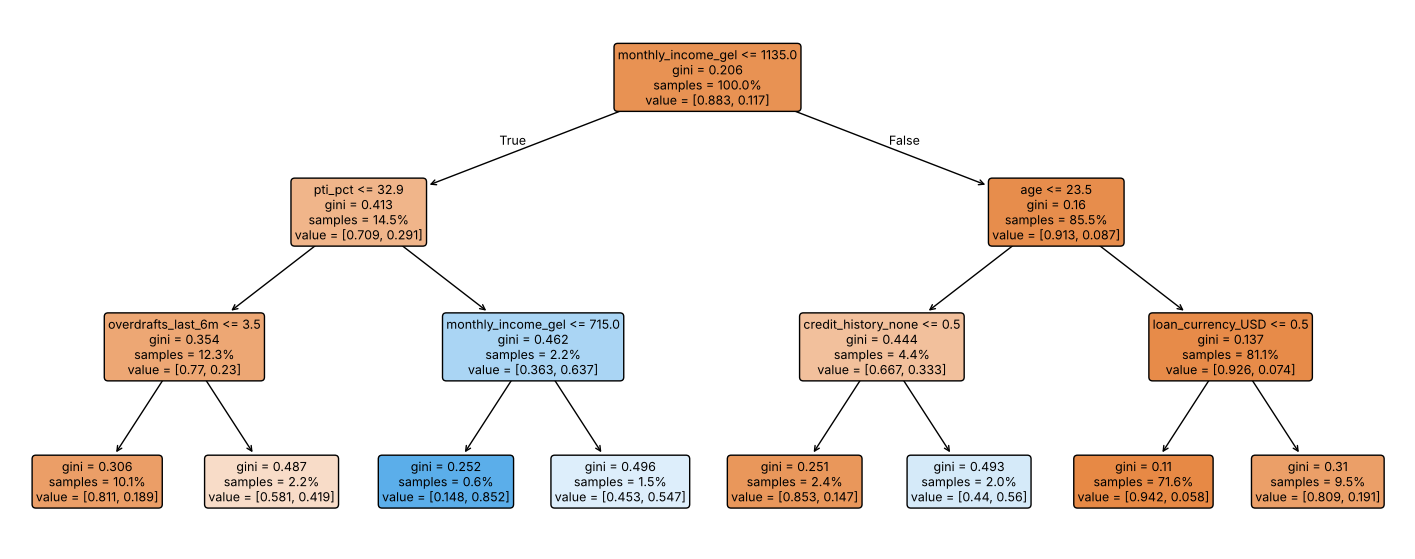

In [6]:
#@title ▶ 3. Model 1: a decision tree you can read
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=X.columns, filled=True, proportion=True, rounded=True, fontsize=9)
plt.show()

Each box asks one yes/no question. The colour shows the share of defaulters in that group. This is the *tree by hand* from the lecture, learned automatically.

## 4. Overfitting: when a model memorises

> 🤔 **Think first** — If we let the tree grow 20 levels deep, will it be better or worse on the **test** set?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

,train AUC,test AUC
depth,,
1,0.622,0.573
2,0.678,0.642
3,0.729,0.676
4,0.761,0.716
5,0.790,0.741
6,0.835,0.737
8,0.891,0.672
10,0.930,0.616
15,0.990,0.615


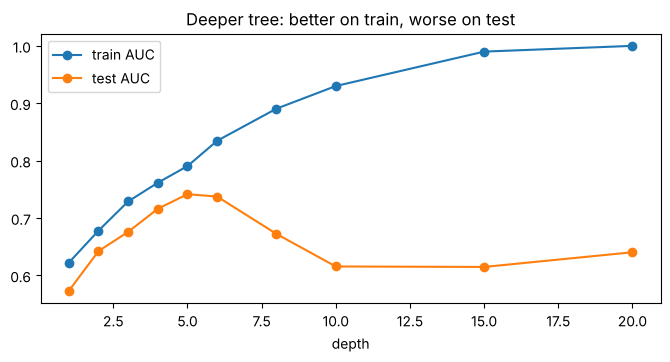

In [7]:
#@title ▶ 4. Overfitting: when a model memorises
from sklearn.metrics import roc_auc_score
rows = []
for depth in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_train, y_train)
    rows.append([depth, roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]), roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])])
curve = pd.DataFrame(rows, columns=["depth", "train AUC", "test AUC"]).set_index("depth")
curve.plot(marker="o", figsize=(8, 3.5), title="Deeper tree: better on train, worse on test"); curve.round(3)

**AUC** (0.5 = coin flip, 1.0 = perfect) measures how well the model *ranks* risky people above safe people. Banks often report **Gini = 2 × AUC − 1**.

The train score keeps rising; the test score peaks and then falls. That gap is **overfitting**.

## 5. Model 2: logistic regression (the classic scorecard)

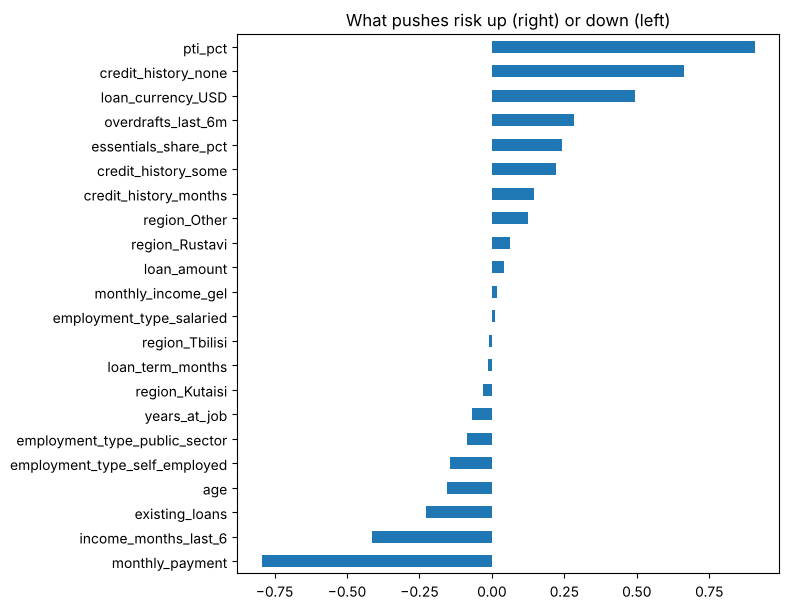

In [8]:
#@title ▶ 5. Model 2: logistic regression (the classic scorecard)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)
coefs = pd.Series(logit[-1].coef_[0], index=X.columns).sort_values()
coefs.plot.barh(figsize=(7, 7), title="What pushes risk up (right) or down (left)");

## 6. Model 3: gradient boosting (many small trees, each fixing the last one's mistakes)

In [9]:
#@title ▶ 6. Model 3: gradient boosting (many small trees, each fixing the last one's mistakes)
from sklearn.ensemble import HistGradientBoostingClassifier
gbm = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0).fit(X_train, y_train)

> 🤔 **Think first** — Which of the three models will have the highest **test** AUC? By how much?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

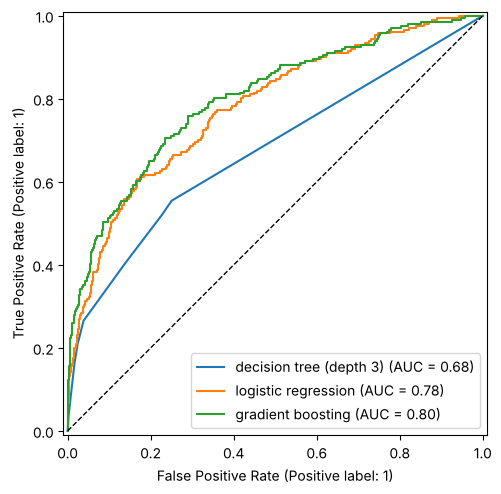

> 🟢 **In plain words:** on the exam (loans never seen in training), the best model ranks the risky person first about **80 times in 100** (AUC 0.80). 50 would be a coin flip.

,model,test AUC,Gini
0,decision tree (depth 3),0.676,0.352
1,logistic regression,0.780,0.560
2,gradient boosting,0.800,0.601


In [10]:
#@title ▶ 6. Model 3: gradient boosting (many small trees, each fixing the last one's mistakes)
from sklearn.metrics import RocCurveDisplay
models = {"decision tree (depth 3)": tree, "logistic regression": logit, "gradient boosting": gbm}
fig, ax = plt.subplots(figsize=(5.5, 5.5))
results = []
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, p)
    results.append([name, round(auc, 3), round(2*auc - 1, 3)])
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=1); plt.show()
say(f"on the exam (loans never seen in training), the best model ranks the risky person first about **{max(r[1] for r in results)*100:.0f} times in 100** (AUC {max(r[1] for r in results):.2f}). 50 would be a coin flip.")
pd.DataFrame(results, columns=["model", "test AUC", "Gini"])

Usually boosting wins, but not by much, and the simpler model is easier to explain to a customer and a regulator. That trade-off is a real decision banks make.

## 7. From probability to decision: the cut-off
The model gives a **PD** for each person. The bank chooses a **cut-off**: approve if PD is below it.

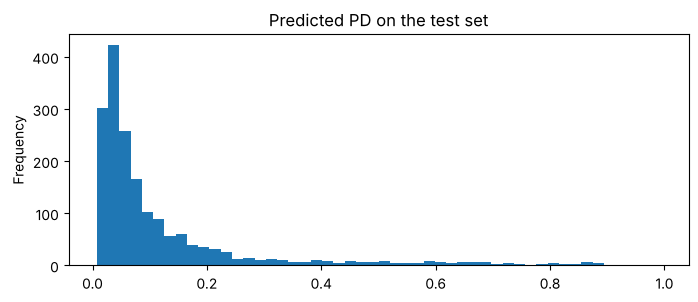

In [11]:
#@title ▶ 7. From probability to decision: the cut-off
pd_test = gbm.predict_proba(X_test)[:, 1]
pd.Series(pd_test).plot.hist(bins=50, figsize=(8, 3), title="Predicted PD on the test set");

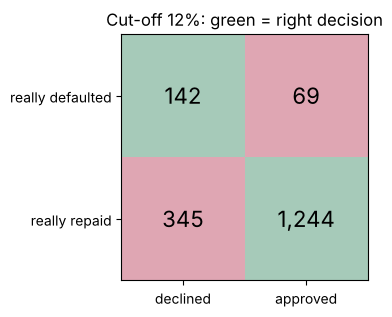

In [12]:
#@title ▶ 7. From probability to decision: the cut-off
from sklearn.metrics import confusion_matrix
def decide(cutoff):
    approve = pd_test < cutoff
    tn, fp, fn, tp = confusion_matrix(y_test, ~approve).ravel()
    return pd.DataFrame([[tp, fn], [fp, tn]],
                        index=["really defaulted", "really repaid"],
                        columns=["declined", "approved"])
cm = decide(0.12)
fig, ax = plt.subplots(figsize=(4.5, 3.2)); ax.imshow([[1, 0], [0, 1]], cmap="RdYlGn", alpha=.35); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, f"{cm.iloc[i, j]:,}", ha="center", va="center", fontsize=16)
ax.set_xticks([0, 1], cm.columns); ax.set_yticks([0, 1], cm.index); ax.set_title("Cut-off 12%: green = right decision"); plt.show()

This is the **confusion matrix**. Two kinds of mistake:
* approved but defaulted (*false negative* for "risky") → the bank loses money;
* declined but would have repaid (*false positive*) → a good customer like Nino is turned away.

> 🤔 **Think first** — Each good loan earns the bank about 600 GEL; each default loses about 5,000 GEL. Which cut-off maximises profit: 5%, 10%, 15% or 25%?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

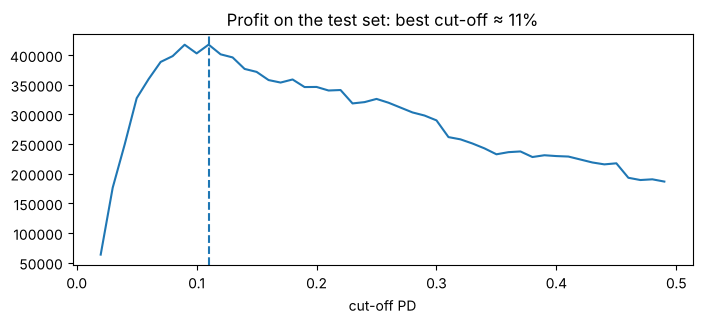

Approval rate at the best cut-off: 70.8 %


> 🟢 **In plain words:** the bank earns most if it approves everyone with a predicted risk below **11%**. That approves **71%** of applicants.

In [13]:
#@title ▶ 7. From probability to decision: the cut-off
GAIN, LOSS = 600, 5000
cutoffs = np.arange(0.02, 0.5, 0.01)
profit = []
for c in cutoffs:
    approve = pd_test < c
    profit.append(GAIN * ((y_test == 0) & approve).sum() - LOSS * ((y_test == 1) & approve).sum())
best = cutoffs[int(np.argmax(profit))]
plt.figure(figsize=(8, 3)); plt.plot(cutoffs, profit); plt.axvline(best, ls="--")
plt.title(f"Profit on the test set: best cut-off ≈ {best:.0%}"); plt.xlabel("cut-off PD"); plt.show()
print("Approval rate at the best cut-off:", round((pd_test < best).mean()*100, 1), "%")
say(f"the bank earns most if it approves everyone with a predicted risk below **{best:.0%}**. That approves **{(pd_test < best).mean():.0%}** of applicants.")

## 8. Score Nino

In [14]:
#@title ▶ 8. Score Nino
new = pd.read_csv(path("credit_new_applicants.csv"))
Xn = pd.get_dummies(new[features], drop_first=True).astype(float).reindex(columns=X.columns, fill_value=0).fillna(X.median())
new["PD_boosting"] = gbm.predict_proba(Xn)[:, 1]
new["PD_logistic"] = logit.predict_proba(Xn)[:, 1]
say(f"Nino's chance of default: **{new.PD_logistic.iloc[0]:.1%}** (scorecard) and **{new.PD_boosting.iloc[0]:.1%}** (boosting). Out of 100 people like her, about {round(new.PD_boosting.iloc[0]*100)} to {round(new.PD_logistic.iloc[0]*100)} would not repay.")
new[["applicant_id", "age", "employment_type", "monthly_income_gel", "credit_history", "PD_logistic", "PD_boosting"]].head(5).round(3)

> 🟢 **In plain words:** Nino's chance of default: **11.3%** (scorecard) and **5.9%** (boosting). Out of 100 people like her, about 6 to 11 would not repay.

,applicant_id,age,employment_type,monthly_income_gel,credit_history,PD_logistic,PD_boosting
0,NINO,27,freelancer,2350.0,none,0.113,0.059
1,N00001,35,salaried,1190.0,some,0.128,0.053
2,N00002,33,salaried,1570.0,long,0.061,0.036
3,N00003,41,salaried,1480.0,some,0.109,0.103
4,N00004,23,salaried,5070.0,none,0.031,0.158


> 🤔 **Think first** — Nino has no credit history, irregular income and few overdrafts. Which of her facts pushes her risk **up** the most?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

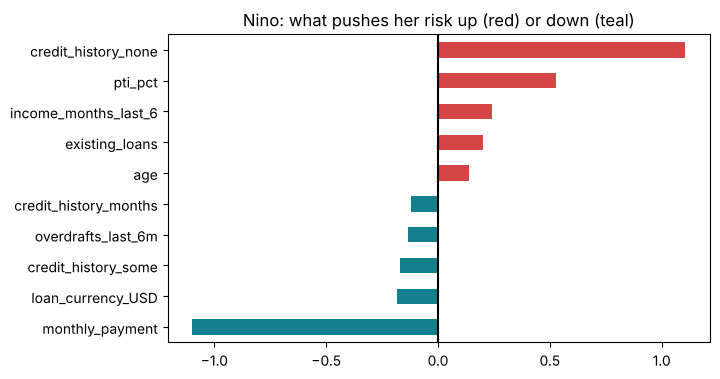

In [15]:
#@title ▶ 8. Score Nino
# Reason codes from the logistic model: contribution = coefficient × (Nino's value − average value), in standard units
scaler, lr = logit[0], logit[-1]
z_nino = (Xn.iloc[[0]].values - scaler.mean_) / scaler.scale_
contrib = pd.Series(lr.coef_[0] * z_nino[0], index=X.columns).sort_values()
show = pd.concat([contrib.head(5), contrib.tail(5)])
show.plot.barh(figsize=(7, 4), color=["#d64545" if v > 0 else "#137f8f" for v in show], title="Nino: what pushes her risk up (red) or down (teal)")
plt.axvline(0, color="k"); plt.show()

The biggest positive contributions are Nino's **reason codes**: what she would be told if declined, and what she can improve. Tools like **SHAP** do the same thing for boosting models (optional cell below).

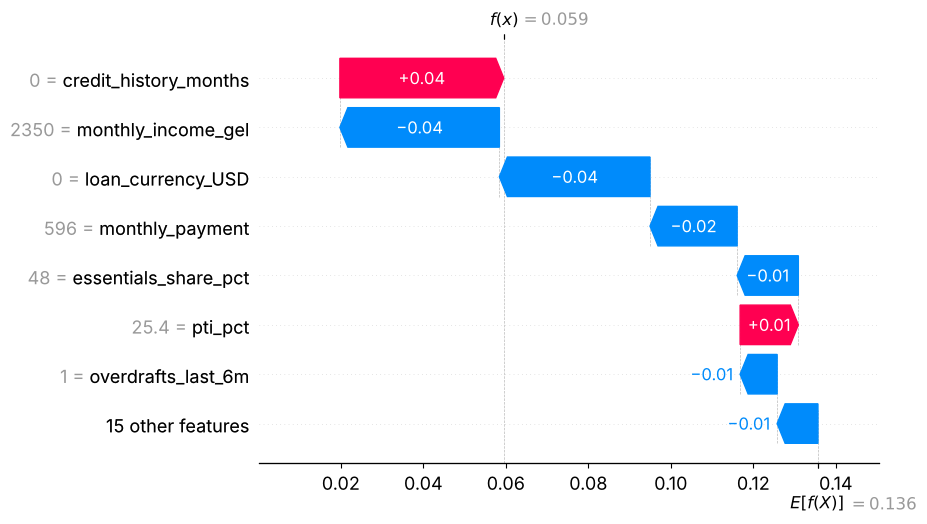

In [16]:
#@title Optional: SHAP explanation for the boosting model
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap
explainer = shap.Explainer(gbm.predict_proba, X_train.sample(100, random_state=0))
sv = explainer(Xn.iloc[[0]])
shap.plots.waterfall(sv[0, :, 1], max_display=8)

## 9. Fairness check

> 🤔 **Think first** — The model never saw `gender`. Can it still treat women and men differently?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

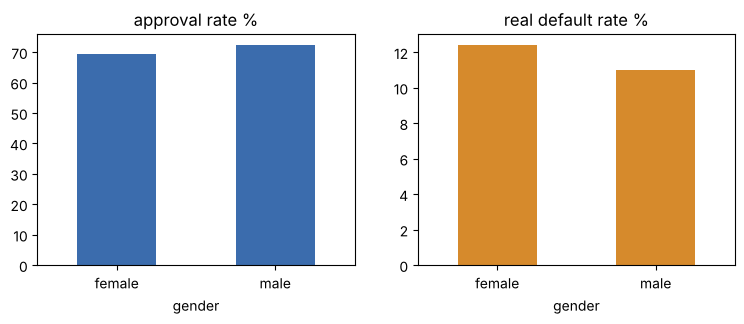

,approval rate %,real default rate %
gender,,
female,69.4,12.4
male,72.3,11.0


In [17]:
#@title ▶ 9. Fairness check
test_people = loans.loc[X_test.index]
approved = pd.Series(pd_test < best, index=X_test.index)
fair = pd.DataFrame({"approval rate %": approved.groupby(test_people.gender).mean()*100,
                     "real default rate %": test_people.groupby("gender").default_12m.mean()*100}).round(1)
fair.plot.bar(subplots=True, layout=(1, 2), figsize=(9, 3), rot=0, legend=False, color=["#3b6cad", "#d68a2c"]); plt.show()
fair

Even without the column, other features (employment type, income) can act as **proxies**. Banks must measure this, explain any gap, and document it. Under NBG model-risk rules this belongs in validation.

## 10. Affordability: the rule the model cannot override

In [18]:
#@title ▶ 10. Affordability: the rule the model cannot override
def pti_limit(net_income, currency="GEL", threshold=1500):
    if currency == "GEL":
        return 25 if net_income < threshold else 50
    return 20 if net_income < threshold else 30
for thr, when in [(1500, "today"), (2000, "from 1 Feb 2027"), (2500, "from 1 Sep 2027")]:
    lim = pti_limit(2350, threshold=thr)
    print(f"{when:16s} limit {lim}%  → largest payment for Nino: {2350*lim/100:.0f} GEL")

today            limit 50%  → largest payment for Nino: 1175 GEL
from 1 Feb 2027  limit 50%  → largest payment for Nino: 1175 GEL
from 1 Sep 2027  limit 25%  → largest payment for Nino: 588 GEL


### ✍️ Your turn

1. Remove `credit_history_months` and `credit_history` from the features and retrain the boosting model. How much does the test AUC drop? What does that tell you about thin-file customers like Nino?
2. **Leakage experiment:** add `collection_calls_after_loan` back. What happens to the AUC? Why would this model fail in real life?
3. Change `LOSS` to 3,000 GEL. How does the best cut-off move?

In [19]:
# your code here

In [20]:
#@title Solution (try first!)
f2 = [f for f in features if f not in ["credit_history_months", "credit_history"]]
X2 = pd.get_dummies(loans[f2], drop_first=True).astype(float).fillna(0)
Xa, Xb, ya, yb = train_test_split(X2, y, test_size=0.3, random_state=1, stratify=y)
m2 = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40).fit(Xa, ya)
print("without credit history:", round(roc_auc_score(yb, m2.predict_proba(Xb)[:, 1]), 3))
X3 = X.copy(); X3["collection_calls_after_loan"] = loans.collection_calls_after_loan
Xa, Xb, ya, yb = train_test_split(X3, y, test_size=0.3, random_state=1, stratify=y)
m3 = HistGradientBoostingClassifier().fit(Xa, ya)
print("with the leaking column:", round(roc_auc_score(yb, m3.predict_proba(Xb)[:, 1]), 3), "← too good to be true")

without credit history: 0.78


with the leaking column: 0.986 ← too good to be true


---
# 🧭 Advanced track · for those who already know ML
**Lecture 1 · credit scoring.** Everything above is the core. What follows is what changes when a model is used inside a bank: things a Kaggle notebook rarely shows. Each block ends with a challenge for your team.

| Block | The banking question |
|---|---|
| A0 · Feature engineering | Turn raw columns into the clues a credit analyst would use: ratios, flags, interactions, information value. |
| A1 · Calibration | Is a PD of 10% really 10%? Provisions (IFRS 9), pricing and capital use the number itself, not the ranking. |
| A2 · Monotonic constraints | Can risk go *down* when overdrafts go up? A validator will ask. |
| A3 · Reason codes you can defend | Do the boosting model's reasons agree with the scorecard's? |
| A4 · Fairness beyond approval rates | Equal approval, equal opportunity, equal calibration: which one, and why you can't have all three. |
| A5 · Reject inference | You only ever see how *approved* people behaved. What does that do to your model? |

## A0 · Feature engineering: build better clues

**Feature engineering** means turning raw columns into clues that say more. The model can only learn from what you give it, and a banker's knowledge enters the model here: *after paying rent, food and the new loan, how much money is left?* is a better question than *what is the income?*

Four kinds of features you will build:

| Kind | Example here | Why |
|---|---|---|
| **Ratio** | loan ÷ annual income | size relative to the person, not absolute GEL |
| **Domain formula** | money left after essentials and the new payment | the question a credit analyst asks |
| **Flag** | thin file (< 12 months of history), income was missing | "missing" or "new" is information |
| **Interaction** | freelancer **and** income in fewer than 6 of 6 months | two facts together mean more than each alone |

> 🤔 **Think first** — Which new clue will separate defaulters best: loan ÷ income, money left after paying, or the thin-file flag?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

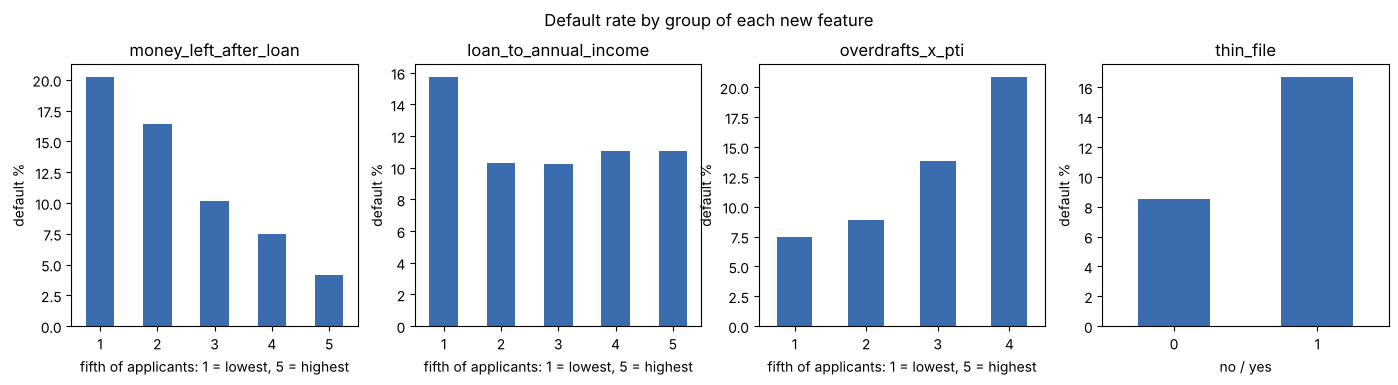

In [21]:
#@title ▶ A0 · Feature engineering: build better clues
fe = loans.copy()
inc = fe.monthly_income_gel.fillna(fe.monthly_income_gel.median())
fe["income_missing"] = loans.monthly_income_gel.isna().astype(int)
fe["money_left_after_loan"] = inc * (1 - fe.essentials_share_pct / 100) - fe.monthly_payment
fe["loan_to_annual_income"] = fe.loan_amount / (inc * 12)
fe["income_stability"] = fe.income_months_last_6 / 6
fe["thin_file"] = (fe.credit_history_months < 12).astype(int)
fe["freelancer_irregular"] = ((fe.employment_type == "freelancer") & (fe.income_months_last_6 < 6)).astype(int)
fe["overdrafts_x_pti"] = fe.overdrafts_last_6m * fe.pti_pct / 100
NEW = ["income_missing", "money_left_after_loan", "loan_to_annual_income", "income_stability", "thin_file", "freelancer_irregular", "overdrafts_x_pti"]

fig, axes = plt.subplots(1, 4, figsize=(17, 3.4))
for ax, col in zip(axes, ["money_left_after_loan", "loan_to_annual_income", "overdrafts_x_pti", "thin_file"]):
    grp = fe[col] if fe[col].nunique() <= 2 else pd.qcut(fe[col], 5, labels=False, duplicates="drop") + 1
    (fe.groupby(grp, observed=True).default_12m.mean() * 100).plot.bar(ax=ax, color="#3b6cad", rot=0)
    ax.set_title(col); ax.set_xlabel("no / yes" if fe[col].nunique() <= 2 else "fifth of applicants: 1 = lowest, 5 = highest"); ax.set_ylabel("default %")
plt.suptitle("Default rate by group of each new feature", y=1.04); plt.show()

### Information value: how much does each clue tell us?
Credit scorecards rank features by **information value (IV)**. Cut a feature into groups, compare the share of good and bad customers in each group (**weight of evidence**, WoE), and add it up.
Rule of thumb: IV < 0.02 useless · 0.02–0.1 weak · 0.1–0.3 medium · > 0.3 strong.

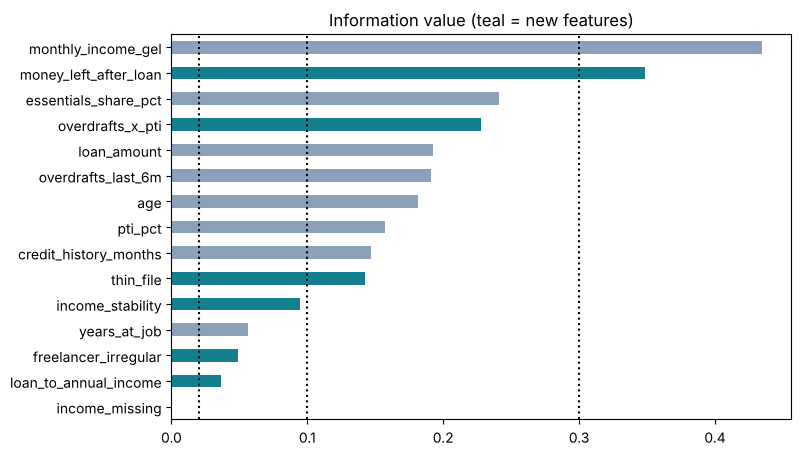

,good %,bad %,WoE
money_left_after_loan,,,
"(-416.601, 299.04]",18.06,34.56,-0.65
"(299.04, 504.52]",18.93,28.03,-0.39
"(504.52, 804.32]",20.35,17.39,0.16
"(804.32, 1378.84]",20.95,12.85,0.49
"(1378.84, 10752.0]",21.71,7.17,1.11


In [22]:
#@title ▶ Information value: how much does each clue tell us?
def woe_iv(col, bins=5):
    g = fe[col] if fe[col].nunique() <= 5 else pd.qcut(fe[col], bins, duplicates="drop")
    t = pd.crosstab(g, fe.default_12m) + 0.5                       # +0.5 avoids dividing by zero
    good, bad = t[0] / t[0].sum(), t[1] / t[1].sum()
    woe = np.log(good / bad)
    return pd.DataFrame({"good %": good * 100, "bad %": bad * 100, "WoE": woe}), float(((good - bad) * woe).sum())
num_raw = ["monthly_income_gel", "pti_pct", "overdrafts_last_6m", "credit_history_months", "essentials_share_pct", "years_at_job", "loan_amount", "age"]
iv = pd.Series({c: woe_iv(c)[1] for c in num_raw + NEW}).sort_values()
iv.plot.barh(figsize=(8, 5), color=["#137f8f" if c in NEW else "#8aa1b9" for c in iv.index], title="Information value (teal = new features)")
for x in [0.02, 0.1, 0.3]: plt.axvline(x, ls=":", color="k")
plt.show()
woe_iv("money_left_after_loan")[0].round(2)

### Does it help the models?

In [23]:
#@title ▶ Does it help the models?
Xfe = pd.get_dummies(fe[features + NEW], drop_first=True).astype(float)
Xfe = Xfe.fillna(Xfe.median())
Xfe_tr, Xfe_te = Xfe.loc[X_train.index], Xfe.loc[X_test.index]          # the same people in train and test as before
cmp = []
for name, mk in [("logistic regression", lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))),
                 ("gradient boosting", lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0))]:
    a = roc_auc_score(y_test, mk().fit(X_train, y_train).predict_proba(X_test)[:, 1])
    b = roc_auc_score(y_test, mk().fit(Xfe_tr, y_train).predict_proba(Xfe_te)[:, 1])
    cmp.append([name, a, b, b - a])
pd.DataFrame(cmp, columns=["model", "test AUC, raw features", "test AUC, + engineered", "gain"]).round(3)

,model,"test AUC, raw features","test AUC, + engineered",gain
0,logistic regression,0.78,0.779,-0.001
1,gradient boosting,0.80,0.798,-0.002


No gain when the models already see **all** raw columns: they can combine income, essentials and payment themselves (and this synthetic data was generated from those raw columns, so there is nothing hidden to find). Now a more realistic banking test: a **small scorecard with only four clues**, the kind a credit committee can read on one page.

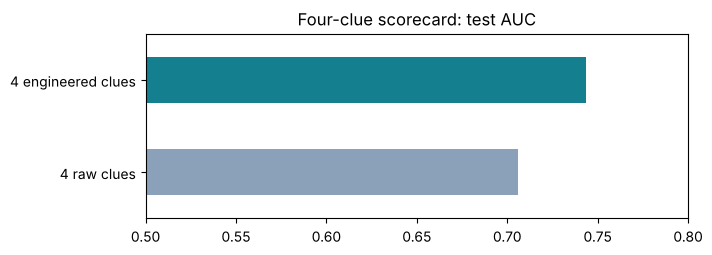

4 raw clues           0.706
4 engineered clues    0.744
dtype: float64

In [24]:
#@title ▶ Does it help the models?
SMALL = {"4 raw clues": ["monthly_income_gel", "pti_pct", "overdrafts_last_6m", "credit_history_months"],
         "4 engineered clues": ["money_left_after_loan", "thin_file", "income_stability", "overdrafts_x_pti"]}
small = {}
for name, cols in SMALL.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xfe_tr[cols], y_train)
    small[name] = roc_auc_score(y_test, m.predict_proba(Xfe_te[cols])[:, 1])
pd.Series(small).plot.barh(figsize=(7, 2.4), color=["#8aa1b9", "#137f8f"], title="Four-clue scorecard: test AUC"); plt.xlim(0.5, 0.8); plt.show()
pd.Series(small).round(3)

With the same number of clues, **engineered features win**: each one packs more banking knowledge. That is the real value of feature engineering: simpler models that are just as good, and reason codes a customer understands. On real data, where the signal is hidden in transactions and documents, it is usually also the biggest source of accuracy gains.

Rules for honest feature engineering:
1. Use only information **known at application time** (never `collection_calls_after_loan`).
2. Compute statistics (medians, bins) on the **training** set when it matters, then apply them to the test set.
3. Each feature should have a **story** you can tell a customer: "money left after paying" is a reason code; "feature_73" is not.

## A1 · Calibration: does the PD mean what it says?

> 🤔 **Think first** — Boosting had the best AUC. Does that mean its PDs are the most accurate numbers?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

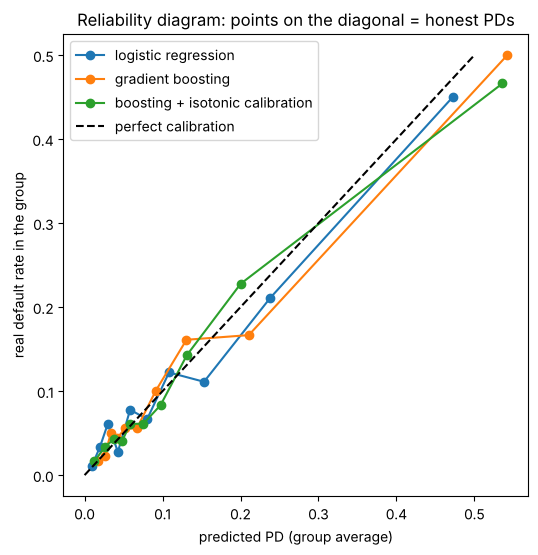

,model,test AUC,Brier score (lower = better),average PD,real default rate
0,logistic regression,0.7799,0.0860,0.1212,0.1172
1,gradient boosting,0.8003,0.0813,0.1212,0.1172
2,boosting + isotonic calibration,0.7983,0.0812,0.1218,0.1172


In [25]:
#@title ▶ A1 · Calibration: does the PD mean what it says?
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.metrics import brier_score_loss
gbm_cal = CalibratedClassifierCV(HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0),
                                 method="isotonic", cv=5).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(6, 6))
rows = []
for name, m in [("logistic regression", logit), ("gradient boosting", gbm), ("boosting + isotonic calibration", gbm_cal)]:
    p = m.predict_proba(X_test)[:, 1]
    frac, mean_p = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_p, frac, "o-", label=name)
    rows.append([name, roc_auc_score(y_test, p), brier_score_loss(y_test, p), p.mean(), y_test.mean()])
ax.plot([0, .5], [0, .5], "k--", label="perfect calibration"); ax.set_xlabel("predicted PD (group average)"); ax.set_ylabel("real default rate in the group")
ax.legend(); ax.set_title("Reliability diagram: points on the diagonal = honest PDs"); plt.show()
pd.DataFrame(rows, columns=["model", "test AUC", "Brier score (lower = better)", "average PD", "real default rate"]).round(4)

**AUC only checks the ranking**; calibration checks the **level**. A model can rank perfectly and still say 5% to people who default 10% of the time, and the bank would under-provision and under-price.
Isotonic calibration re-maps the scores to match observed rates without changing the ranking much. In production you calibrate on recent data and re-check every quarter.

## A2 · Monotonic constraints: make the model obey common sense

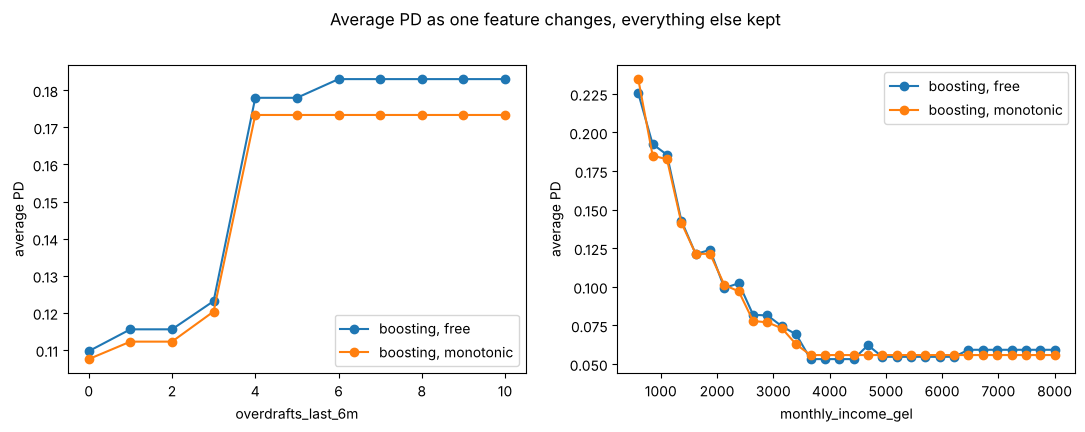

test AUC  free: 0.8   monotonic: 0.793


In [26]:
#@title ▶ A2 · Monotonic constraints: make the model obey common sense
mono = {"overdrafts_last_6m": 1, "pti_pct": 1, "existing_loans": 1, "essentials_share_pct": 1,
        "monthly_income_gel": -1, "credit_history_months": -1, "income_months_last_6": -1, "years_at_job": -1}
cst = [mono.get(col, 0) for col in X.columns]
gbm_mono = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40,
                                          monotonic_cst=cst, random_state=0).fit(X_train, y_train)

def effect(model, col, values, n=600):
    base = X_test.sample(n, random_state=0).copy(); out = []
    for v in values:
        base[col] = v; out.append(model.predict_proba(base)[:, 1].mean())
    return np.array(out)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, vals in [(axes[0], "overdrafts_last_6m", np.arange(0, 11)), (axes[1], "monthly_income_gel", np.linspace(600, 8000, 30))]:
    ax.plot(vals, effect(gbm, col, vals), "o-", label="boosting, free")
    ax.plot(vals, effect(gbm_mono, col, vals), "o-", label="boosting, monotonic")
    ax.set_xlabel(col); ax.set_ylabel("average PD"); ax.legend()
plt.suptitle("Average PD as one feature changes, everything else kept", y=1.02); plt.show()
print("test AUC  free:", round(roc_auc_score(y_test, gbm.predict_proba(X_test)[:, 1]), 3),
      "  monotonic:", round(roc_auc_score(y_test, gbm_mono.predict_proba(X_test)[:, 1]), 3))

A free model may learn wiggles from noise: look at the right plot above 6,000 GEL, where the free model says *richer = slightly riskier*. A customer, a regulator or a judge will not accept that. Monotonic constraints cost almost no AUC and make the model **defensible**: one of the first things a model validator checks.

## A3 · Reason codes you can defend

> 🤔 **Think first** — For a declined applicant, will the boosting model and the scorecard name the same top reasons?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

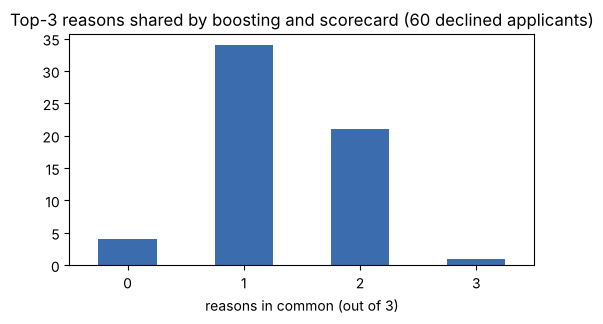

Example: boosting → ['age', 'credit_history_months', 'pti_pct'] | scorecard → ['credit_history_none', 'pti_pct', 'region_Other']


In [27]:
#@title ▶ A3 · Reason codes you can defend
med = X_train.median()
def reasons_occlusion(model, row, top=3):
    # model-agnostic: how much does PD fall if this feature were set to a typical value?
    p0 = model.predict_proba(row)[:, 1][0]; drops = {}
    for col in X.columns:
        r = row.copy(); r[col] = med[col]; drops[col] = p0 - model.predict_proba(r)[:, 1][0]
    return [k for k, v in sorted(drops.items(), key=lambda kv: -kv[1])[:top] if v > 0]
def reasons_logit(row, top=3):
    z = (row.values[0] - logit[0].mean_) / logit[0].scale_
    c = pd.Series(logit[-1].coef_[0] * z, index=X.columns)
    return list(c[c > 0].sort_values(ascending=False).index[:top])
declined = X_test[pd_test >= best].sample(60, random_state=0)
agree = [len(set(reasons_occlusion(gbm, declined.iloc[[i]])) & set(reasons_logit(declined.iloc[[i]]))) for i in range(len(declined))]
pd.Series(agree).value_counts().sort_index().plot.bar(rot=0, color="#3b6cad", figsize=(6, 3), title="Top-3 reasons shared by boosting and scorecard (60 declined applicants)")
plt.xlabel("reasons in common (out of 3)"); plt.show()
print("Example:", "boosting →", reasons_occlusion(gbm, declined.iloc[[0]]), "| scorecard →", reasons_logit(declined.iloc[[0]]))

When the two disagree, which explanation do you give the customer? Banks usually keep the **scorecard for explanations** and use boosting as a challenger, or constrain boosting (A2) until its reasons are stable. SHAP (optional cell in Section 8) is the standard tool; the occlusion method above is a simpler check that works for any model.

## A4 · Fairness beyond approval rates

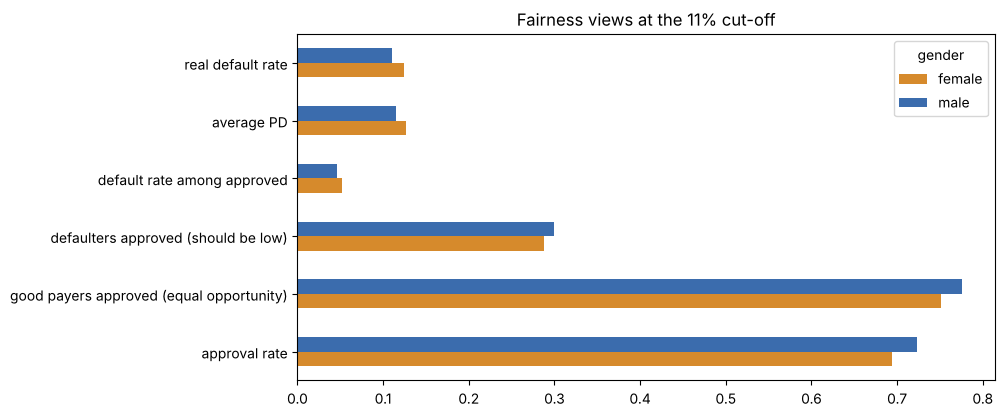

gender,female,male
approval rate,0.694,0.723
good payers approved (equal opportunity),0.751,0.775
defaulters approved (should be low),0.288,0.300
default rate among approved,0.052,0.046
average PD,0.127,0.115
real default rate,0.124,0.110


In [28]:
#@title ▶ A4 · Fairness beyond approval rates
tp = loans.loc[X_test.index]; appr = pd.Series(pd_test < best, index=X_test.index); good = tp.default_12m == 0
pdt = pd.Series(pd_test, index=X_test.index)
fm = pd.DataFrame({
    "approval rate": appr.groupby(tp.gender).mean(),
    "good payers approved (equal opportunity)": appr[good].groupby(tp.gender[good]).mean(),
    "defaulters approved (should be low)": appr[~good].groupby(tp.gender[~good]).mean(),
    "default rate among approved": tp.default_12m[appr].groupby(tp.gender[appr]).mean(),
    "average PD": pdt.groupby(tp.gender).mean(),
    "real default rate": tp.default_12m.groupby(tp.gender).mean()}).T
fm.plot.barh(figsize=(9, 4.5), color=["#d68a2c", "#3b6cad"], title=f"Fairness views at the {best:.0%} cut-off"); plt.show()
fm.round(3)

Three common definitions:
* **Demographic parity**: same approval rate for each group.
* **Equal opportunity**: good payers approved at the same rate in each group.
* **Calibration**: the same PD means the same risk in each group.

When groups have **different real default rates**, these cannot all hold at once (a known result). So fairness is a **choice you document**: which definition, why, and what gap you accept. Under the EU AI Act credit scoring is high-risk, and this table is the kind of evidence a validator expects.

## A5 · Reject inference: the people you never see

> 🤔 **Think first** — Your training data only has outcomes for people the bank approved in the past. What does a model trained on them believe about the people the bank used to decline?
>
> *Write your guess in the box below before running the next cell.*

✏️ *My guess:* 

In [29]:
#@title ▶ A5 · Reject inference: the people you never see
old_cols = ["monthly_income_gel", "overdrafts_last_6m", "pti_pct"]
old_policy = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train[old_cols], y_train)
old_pd = old_policy.predict_proba(X_train[old_cols])[:, 1]
seen = old_pd < np.quantile(old_pd, 0.70)                  # the old policy approved 70%: only their outcomes are known
m_seen = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=40, random_state=0).fit(X_train[seen], y_train[seen])

old_test = old_policy.predict_proba(X_test[old_cols])[:, 1] >= np.quantile(old_pd, 0.70)   # people the old policy would decline
res = pd.DataFrame({
    "trained on everyone (impossible in real life)": [roc_auc_score(y_test, gbm.predict_proba(X_test)[:, 1]), gbm.predict_proba(X_test[old_test])[:, 1].mean()],
    "trained on approved only (real life)": [roc_auc_score(y_test, m_seen.predict_proba(X_test)[:, 1]), m_seen.predict_proba(X_test[old_test])[:, 1].mean()]},
    index=["test AUC, all applicants", "average PD it gives the previously-declined"]).T
res["real default rate of the previously-declined"] = y_test[old_test].mean()
res.round(3)

,"test AUC, all applicants",average PD it gives the previously-declined,real default rate of the previously-declined
trained on everyone (impossible in real life),0.800,0.211,0.202
trained on approved only (real life),0.772,0.140,0.202


A model trained only on approved customers has never seen what happens to the risky ones, so it **underestimates** their risk (compare the last two columns). If the bank then loosens its policy, defaults come as a surprise.
Fixes used in practice: approve a small **random test group** below the cut-off (*test-and-learn*), use **credit-bureau outcomes** of declined applicants at other banks, or statistical **augmentation / parceling**. Our synthetic data has outcomes for everyone, which is why we can measure the bias here; real data never does.

### ✍️ Your turn

**Team challenges (pick one for your AI1 pitch):**
1. Engineer three features for your own product idea, show their information value, and keep only the ones with a story.
2. Build a model card section *Calibration*: reliability diagram before and after calibration, and the Brier score.
3. Add monotonic constraints to your best model. Report the AUC cost and show one plot that a regulator would understand.
4. Choose a fairness definition for your product, justify it in two sentences, and show the table for it.
5. Simulate a test-and-learn policy: approve a random 5% below the cut-off for one quarter. How many extra defaults does it cost, and what do you learn?

In [30]:
# your code here

## 🚀 Take it further on Kaggle
Run the same recipe on a real public dataset. Good ones to start with (search the name on kaggle.com):
* **Credit Risk Dataset** (`laotse/credit-risk-dataset`, ~32,000 loans, target `loan_status`)
* **German Credit** (`uciml/german-credit`, 1,000 applicants, a classic)
* **Home Credit Default Risk** (competition, large and realistic, for advanced teams)

Change `KAGGLE_DATASET` in the loader, then the file name and `TARGET`.

### What you learned
features · leakage · one-hot encoding · train/test split · decision tree · overfitting · AUC and Gini · logistic regression · gradient boosting · PD · confusion matrix · cut-off and profit · reason codes / SHAP · fairness and proxies · PTI.